In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('loan_approval_dataset.csv')

In [3]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## EDA

In [4]:
df.shape

(4269, 13)

In [5]:
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [7]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [10]:
df.columns.tolist()

['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [11]:
df.columns = df.columns.str.strip()

In [12]:
df.columns.tolist()

['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

In [13]:
df.drop(["loan_id"], axis=1, inplace=True)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          4269 non-null   int64 
 1   education                 4269 non-null   object
 2   self_employed             4269 non-null   object
 3   income_annum              4269 non-null   int64 
 4   loan_amount               4269 non-null   int64 
 5   loan_term                 4269 non-null   int64 
 6   cibil_score               4269 non-null   int64 
 7   residential_assets_value  4269 non-null   int64 
 8   commercial_assets_value   4269 non-null   int64 
 9   luxury_assets_value       4269 non-null   int64 
 10  bank_asset_value          4269 non-null   int64 
 11  loan_status               4269 non-null   object
dtypes: int64(9), object(3)
memory usage: 400.3+ KB


<Axes: xlabel='loan_status', ylabel='count'>

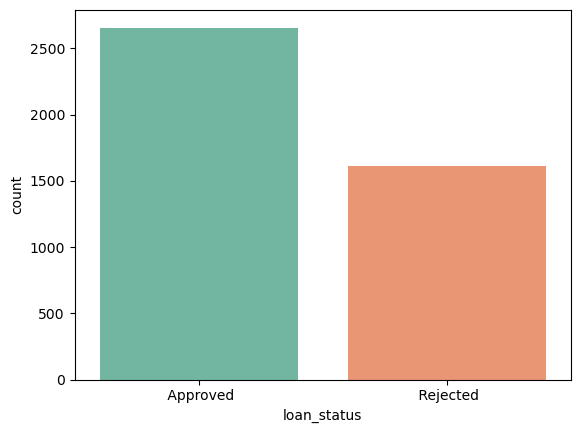

In [15]:
df['loan_status'].value_counts()
sns.countplot(x = 'loan_status', data=df, palette='Set2')

In [16]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


array([[<Axes: title={'center': 'income_annum'}>,
        <Axes: title={'center': 'loan_amount'}>,
        <Axes: title={'center': 'loan_term'}>],
       [<Axes: title={'center': 'cibil_score'}>,
        <Axes: title={'center': 'residential_assets_value'}>,
        <Axes: title={'center': 'commercial_assets_value'}>],
       [<Axes: title={'center': 'luxury_assets_value'}>,
        <Axes: title={'center': 'bank_asset_value'}>, <Axes: >]],
      dtype=object)

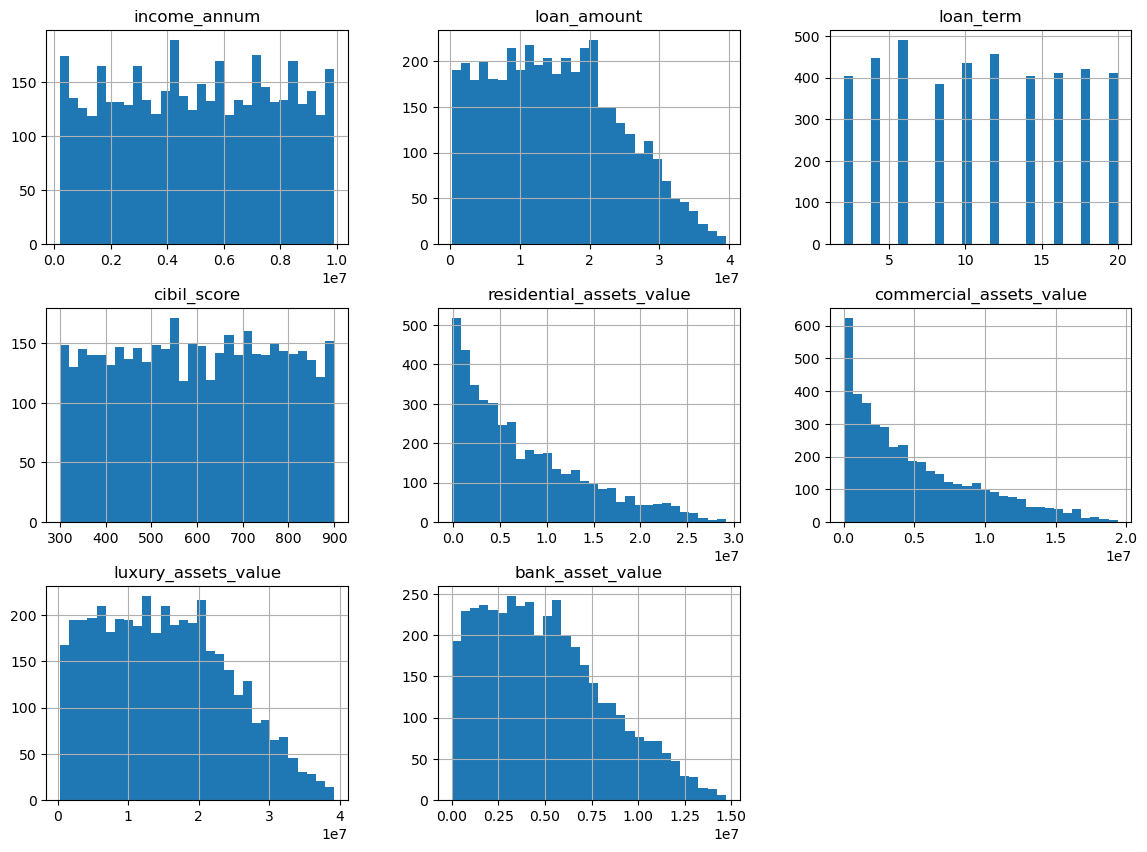

In [17]:
numerical_cols = ['income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

df[numerical_cols].hist(bins= 30, figsize=(14, 10))

<Axes: xlabel='self_employed', ylabel='count'>

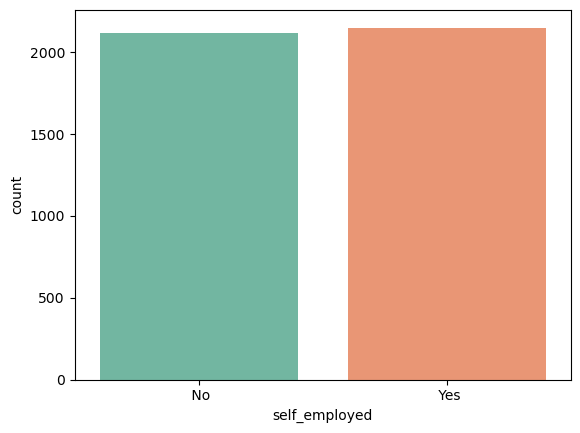

In [18]:
sns.countplot(data=df, x='self_employed', palette='Set2')

<Axes: xlabel='loan_status', ylabel='cibil_score'>

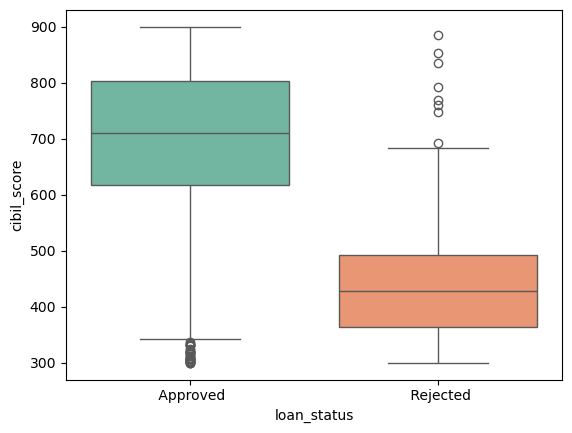

In [19]:
sns.boxplot(x = 'loan_status', y = 'cibil_score', data=df, palette='Set2')

In [20]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


<Axes: >

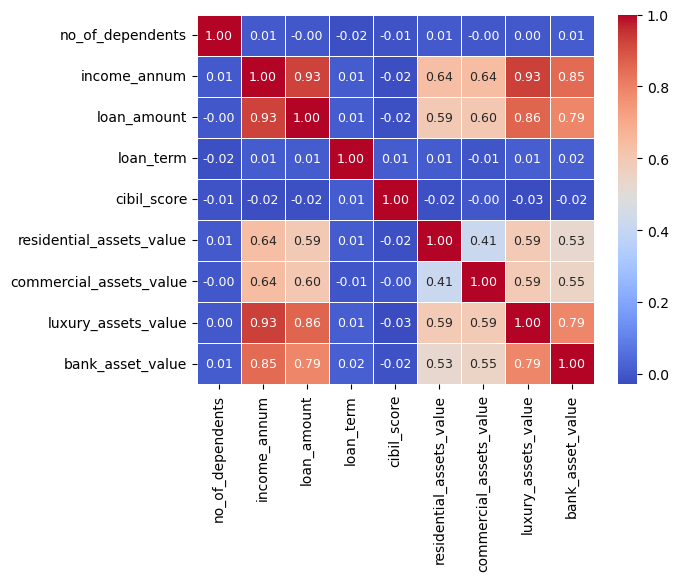

In [21]:
sns.heatmap(df.corr(numeric_only=True), fmt='.2f', annot_kws= {'size': 9}, cmap= 'coolwarm',linewidths=0.5, annot= True)

In [22]:
numerical_cols = df.select_dtypes(include='number').columns
num_data = df[numerical_cols]
Q1 = num_data.quantile(0.25)
Q3 = num_data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_data < lower_bound) | (num_data > upper_bound)
print(outliers.sum())

no_of_dependents             0
income_annum                 0
loan_amount                  0
loan_term                    0
cibil_score                  0
residential_assets_value    52
commercial_assets_value     37
luxury_assets_value          0
bank_asset_value             5
dtype: int64


## Data Cleaning & Feature Engineering

In [23]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [24]:
df = df.drop_duplicates()

df['residential_assets_value'] = df['residential_assets_value'].clip(lower=0)

In [25]:
df['loan_status'] = df['loan_status'].str.strip()

In [26]:
df.describe()

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.473272e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.502878e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,0.000000e+00,0.000000e+00,3.000000e+05,0.000000e+00
25%,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [27]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()

no_of_dependents           -0.017971
income_annum               -0.012814
loan_amount                 0.308724
loan_term                   0.036359
cibil_score                -0.009039
residential_assets_value    0.978896
commercial_assets_value     0.957791
luxury_assets_value         0.322208
bank_asset_value            0.560725
dtype: float64

## Train Test Split

In [28]:
from sklearn.model_selection import train_test_split

skewed_cols = ['residential_assets_value', 'commercial_assets_value', 'bank_asset_value']
other_numerical_cols = ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'luxury_assets_value']
categorical_cols = ['education', 'self_employed']

feature_cols = skewed_cols + other_numerical_cols + categorical_cols
x = df[feature_cols]
y = df['loan_status']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

In [29]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_xg = le.fit_transform(y_train)
y_test_xg = le.transform(y_test)

print(le.classes_)

['Approved' 'Rejected']


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

#1. Skewed Feature 
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)), 
    ('scale', StandardScaler())
])

#2. Numerical Feature 
numerical_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])

#3.  Categorical Feature 
categorical_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])


preprocessor = ColumnTransformer(transformers=[
    ('Skewed_Pipeline', skew_pipeline, skewed_cols),
    ('Plain_Numerical', numerical_pipeline, other_numerical_cols), 
    ('Normal_Categorical', categorical_pipeline, categorical_cols)
])

In [31]:
preprocessor

,transformers,"[('Skewed_Pipeline', ...), ('Plain_Numerical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,func,<ufunc 'log1p'>
,inverse_func,None
,validate,False


## BaseLine: Logistic Regression

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score


lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression()), 
    #('model', RandomForestClassifier())
])

lr_pipeline.fit(x_train, y_train)
lr_preds_test = lr_pipeline.predict(x_test)
lr_preds_train = lr_pipeline.predict(x_train)
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]

lr_accuracy_testing = accuracy_score(y_test, lr_preds_test)
lr_accuracy_training = accuracy_score(y_train, lr_preds_train)
lr_precision = precision_score(y_test, lr_preds_test, pos_label='Approved')
lr_recall = recall_score(y_test, lr_preds_test, pos_label='Approved')
lr_f1 = f1_score(y_test, lr_preds_test, pos_label='Approved')
lr_confusion = confusion_matrix(y_test, lr_preds_test)
lr_auc = roc_auc_score(y_test, lr_proba)

print(f'Accuracy of Training =>  {lr_accuracy_training}')
print(f'Accuracy of Testing =>   {lr_accuracy_testing}')
print(f'Accuracy of Precision => {lr_precision}')
print(f'Accuracy of Recall =>    {lr_recall}')
print(f'Accuracy of F1 =>        {lr_f1}')
print(f'Accuracy of Confusion => {lr_confusion}')
print(f'Accuracy of ROC AUC =>   {lr_auc}')

Accuracy of Training =>  0.9216867469879518
Accuracy of Testing =>   0.8985167837626854
Accuracy of Precision => 0.9176904176904177
Accuracy of Recall =>    0.9222222222222223
Accuracy of F1 =>        0.9199507389162561
Accuracy of Confusion => [[747  63]
 [ 67 404]]
Accuracy of ROC AUC =>   0.9633089565149013


# Random Forest MODEL

In [33]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier 

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('random forest', RandomForestClassifier(random_state=42))
])

rf_pipeline.fit(x_train, y_train)  
rf_preds_test = rf_pipeline.predict(x_test)
rf_preds_train = rf_pipeline.predict(x_train)
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]

rf_accuracy_testing = accuracy_score(y_test, rf_preds_test)
rf_accuracy_training = accuracy_score(y_train, rf_preds_train)
rf_precision = precision_score(y_test, rf_preds_test, pos_label='Approved')
rf_recall = recall_score(y_test, rf_preds_test, pos_label='Approved')
rf_f1 = f1_score(y_test, rf_preds_test, pos_label='Approved')
rf_confusion = confusion_matrix(y_test, rf_preds_test)
rf_auc = roc_auc_score(y_test, rf_proba)

print(f'Accuracy of Training =>  {rf_accuracy_training}')
print(f'Accuracy of Testing =>   {rf_accuracy_testing}')
print(f'Accuracy of Precision => {rf_precision}')
print(f'Accuracy of Recall =>    {rf_recall}')
print(f'Accuracy of F1 =>        {rf_f1}')
print(f'Accuracy of Confusion => {rf_confusion}')
print(f'Accuracy of ROC AUC =>   {rf_auc}')

Accuracy of Training =>  1.0
Accuracy of Testing =>   0.9773614363778298
Accuracy of Precision => 0.9791411042944785
Accuracy of Recall =>    0.9851851851851852
Accuracy of F1 =>        0.9821538461538462
Accuracy of Confusion => [[798  12]
 [ 17 454]]
Accuracy of ROC AUC =>   0.9972254986763126


## Decision Tree MODEL

In [34]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('decision_tree', DecisionTreeClassifier(random_state=42, max_depth=5, min_samples_split=20, min_samples_leaf=10, max_features='sqrt'))
])

dt_pipeline.fit(x_train, y_train)
dt_preds_test = dt_pipeline.predict(x_test)
dt_preds_train = dt_pipeline.predict(x_train)
dt_proba = dt_pipeline.predict_proba(x_test)[:, 1]

dt_accuracy_testing = accuracy_score(y_test, dt_preds_test)
dt_accuracy_training = accuracy_score(y_train, dt_preds_train)
dt_precision = precision_score(y_test, dt_preds_test, pos_label='Approved')
dt_recall = recall_score(y_test, dt_preds_test, pos_label='Approved')
dt_f1 = f1_score(y_test, dt_preds_test, pos_label='Approved')
dt_confusion = confusion_matrix(y_test, dt_preds_test)
dt_auc = roc_auc_score(y_test, dt_proba)

print(f'Accuracy of Training =>  {dt_accuracy_training}')
print(f'Accuracy of Testing =>   {dt_accuracy_testing}')
print(f'Accuracy of Precision => {dt_precision}')
print(f'Accuracy of Recall =>    {dt_recall}')
print(f'Accuracy of F1 =>        {dt_f1}')
print(f'Accuracy of Confusion => {dt_confusion}')
print(f'Accuracy of ROC AUC =>   {dt_auc}')

Accuracy of Training =>  0.9344042838018741
Accuracy of Testing =>   0.9258391881342701
Accuracy of Precision => 0.9200940070505288
Accuracy of Recall =>    0.9666666666666667
Accuracy of F1 =>        0.9428055388320289
Accuracy of Confusion => [[783  27]
 [ 68 403]]
Accuracy of ROC AUC =>   0.9684411942019868


## Gradient Boosting MODEL

In [35]:
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('gradient_boost', GradientBoostingClassifier(random_state=42))
])

gb_pipeline.fit(x_train, y_train)
gb_preds_test = gb_pipeline.predict(x_test)
gb_preds_train = gb_pipeline.predict(x_train)
gb_proba = gb_pipeline.predict_proba(x_test)[:, 1]

gb_accuracy_testing = accuracy_score(y_test, gb_preds_test)
gb_accuracy_training = accuracy_score(y_train, gb_preds_train)
gb_precision = precision_score(y_test, gb_preds_test, pos_label='Approved')
gb_recall = recall_score(y_test, gb_preds_test, pos_label='Approved')
gb_f1 = f1_score(y_test, gb_preds_test, pos_label='Approved')
gb_confusion = confusion_matrix(y_test, gb_preds_test)
gb_auc = roc_auc_score(y_test, gb_proba)

print(f'Accuracy of Training =>  {gb_accuracy_training}')
print(f'Accuracy of Testing =>   {gb_accuracy_testing}')
print(f'Accuracy of Precision => {gb_precision}')
print(f'Accuracy of Recall =>    {gb_recall}')
print(f'Accuracy of F1 =>        {gb_f1}')
print(f'Accuracy of Confusion => {gb_confusion}')
print(f'Accuracy of ROC AUC =>   {gb_auc}')

Accuracy of Training =>  0.9959839357429718
Accuracy of Testing =>   0.9742388758782201
Accuracy of Precision => 0.969770253929867
Accuracy of Recall =>    0.9901234567901235
Accuracy of F1 =>        0.9798411728772144
Accuracy of Confusion => [[802   8]
 [ 25 446]]
Accuracy of ROC AUC =>   0.9974784409320857


## Extra Tree MODEL

In [36]:
et_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('extra_tree', ExtraTreesClassifier(n_estimators=300, random_state=42, max_depth=8, min_samples_leaf=5, max_features='sqrt'))
])

et_pipeline.fit(x_train, y_train)
et_preds_test = et_pipeline.predict(x_test)
et_preds_train = et_pipeline.predict(x_train)
et_proba = et_pipeline.predict_proba(x_test)[:, 1]

et_accuracy_testing = accuracy_score(y_test, et_preds_test)
et_accuracy_training = accuracy_score(y_train, et_preds_train)
et_precision = precision_score(y_test, et_preds_test, pos_label='Approved')
et_recall = recall_score(y_test, et_preds_test, pos_label='Approved')
et_f1 = f1_score(y_test, et_preds_test, pos_label='Approved')
et_confusion = confusion_matrix(y_test, et_preds_test)
et_auc = roc_auc_score(y_test, et_proba)

print(f'Accuracy of Training =>  {et_accuracy_training}')
print(f'Accuracy of Testing =>   {et_accuracy_testing}')
print(f'Accuracy of Precision => {et_precision}')
print(f'Accuracy of Recall =>    {et_recall}')
print(f'Accuracy of F1 =>        {et_f1}')
print(f'Accuracy of Confusion => {et_confusion}')
print(f'Accuracy of ROC AUC =>   {et_auc}')

Accuracy of Training =>  0.9534805890227577
Accuracy of Testing =>   0.9305230288836847
Accuracy of Precision => 0.9390986601705238
Accuracy of Recall =>    0.9518518518518518
Accuracy of F1 =>        0.9454322501532803
Accuracy of Confusion => [[771  39]
 [ 50 421]]
Accuracy of ROC AUC =>   0.9840397368352074


## Knn MODEL

In [37]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(x_train, y_train)
knn_preds_test = knn_pipeline.predict(x_test)
knn_preds_train = knn_pipeline.predict(x_train)
knn_proba = knn_pipeline.predict_proba(x_test)[:, 1]

knn_accuracy_testing = accuracy_score(y_test, knn_preds_test)
knn_accuracy_training = accuracy_score(y_train, knn_preds_train)
knn_precision = precision_score(y_test, knn_preds_test, pos_label='Approved')
knn_recall = recall_score(y_test, knn_preds_test, pos_label='Approved')
knn_f1 = f1_score(y_test, knn_preds_test, pos_label='Approved')
knn_confusion = confusion_matrix(y_test, knn_preds_test)
knn_auc = roc_auc_score(y_test, knn_proba)

print(f'Accuracy of Training =>  {knn_accuracy_training}')
print(f'Accuracy of Testing =>   {knn_accuracy_testing}')
print(f'Accuracy of Precision => {knn_precision}')
print(f'Accuracy of Recall =>    {knn_recall}')
print(f'Accuracy of F1 =>        {knn_f1}')
print(f'Accuracy of Confusion => {knn_confusion}')
print(f'Accuracy of ROC AUC =>   {knn_auc}')

Accuracy of Training =>  0.9464524765729585
Accuracy of Testing =>   0.8907103825136612
Accuracy of Precision => 0.9219143576826196
Accuracy of Recall =>    0.9037037037037037
Accuracy of F1 =>        0.912718204488778
Accuracy of Confusion => [[732  78]
 [ 62 409]]
Accuracy of ROC AUC =>   0.9601058949961994


## SVM MODEL

In [38]:
from sklearn.svm import SVC

svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('svm', SVC(probability=True,random_state=42))
])

svm_pipeline.fit(x_train, y_train)
svm_preds_test = svm_pipeline.predict(x_test)
svm_preds_train = svm_pipeline.predict(x_train)
svm_proba = svm_pipeline.predict_proba(x_test)[:, 1]

svm_accuracy_testing = accuracy_score(y_test, svm_preds_test)
svm_accuracy_training = accuracy_score(y_train, svm_preds_train)
svm_precision = precision_score(y_test, svm_preds_test, pos_label='Approved')
svm_recall = recall_score(y_test, svm_preds_test, pos_label='Approved')
svm_f1 = f1_score(y_test, svm_preds_test, pos_label='Approved')
svm_confusion = confusion_matrix(y_test, svm_preds_test)
svm_auc = roc_auc_score(y_test, svm_proba)

print(f'Accuracy of Training =>  {svm_accuracy_training}')
print(f'Accuracy of Testing =>   {svm_accuracy_testing}')
print(f'Accuracy of Precision => {svm_precision}')
print(f'Accuracy of Recall =>    {svm_recall}')
print(f'Accuracy of F1 =>        {svm_f1}')
print(f'Accuracy of Confusion => {svm_confusion}')
print(f'Accuracy of ROC AUC =>   {svm_auc}')

Accuracy of Training =>  0.9578313253012049
Accuracy of Testing =>   0.9281811085089774
Accuracy of Precision => 0.9532828282828283
Accuracy of Recall =>    0.9320987654320988
Accuracy of F1 =>        0.9425717852684145
Accuracy of Confusion => [[755  55]
 [ 37 434]]
Accuracy of ROC AUC =>   0.9831432989960944


## XG Boosting MODEL

In [39]:
from xgboost import XGBClassifier

xg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('xg_boost', XGBClassifier(n_estimators=300, learning_rate=0.05, random_state=42, max_depth=5, eval_meric='logloss'))
])

xg_pipeline.fit(x_train, y_train_xg)
xg_preds_test = xg_pipeline.predict(x_test)
xg_preds_train = xg_pipeline.predict(x_train)
xg_proba = xg_pipeline.predict_proba(x_test)[:, 1]

xg_accuracy_testing = accuracy_score(y_test_xg, xg_preds_test)
xg_accuracy_training = accuracy_score(y_train_xg, xg_preds_train)
xg_precision = precision_score(y_test_xg, xg_preds_test)
xg_recall = recall_score(y_test_xg, xg_preds_test)
xg_f1 = f1_score(y_test_xg, xg_preds_test)
xg_confusion = confusion_matrix(y_test_xg, xg_preds_test)
xg_auc = roc_auc_score(y_test_xg, xg_proba)

print(f'Accuracy of Training =>  {xg_accuracy_training}')
print(f'Accuracy of Testing =>   {xg_accuracy_testing}')
print(f'Accuracy of Precision => {xg_precision}')
print(f'Accuracy of Recall =>    {xg_recall}')
print(f'Accuracy of F1 =>        {xg_f1}')
print(f'Accuracy of Confusion => {xg_confusion}')
print(f'Accuracy of ROC AUC =>   {xg_auc}')

Accuracy of Training =>  1.0
Accuracy of Testing =>   0.9773614363778298
Accuracy of Precision => 0.9722222222222222
Accuracy of Recall =>    0.9660297239915074
Accuracy of F1 =>        0.9691160809371672
Accuracy of Confusion => [[797  13]
 [ 16 455]]
Accuracy of ROC AUC =>   0.9975990144426097


In [40]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'random forest__n_estimators'        : [100, 200, 300],
    'random forest__max_depth'           : [5, 10, 15],
    'random forest__min_samples_split'  : [2, 5, 10],
    'random forest__min_samples_leaf'    : [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator= rf_pipeline, 
    param_distributions= param_grid, 
    n_iter= 15, 
    cv= 5, 
    scoring= 'r2', 
    random_state= 42, 
    n_jobs= -1  #processor free
)

random_search.fit(x_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'random forest__max_depth': [5, 10, ...], 'random forest__min_samples_leaf': [1, 2, ...], 'random forest__min_samples_split': [2, 5, ...], 'random forest__n_estimators': [100, 200, ...]}"
,n_iter,15
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [41]:
random_search.best_params_

{'random forest__n_estimators': 100,
 'random forest__min_samples_split': 5,
 'random forest__min_samples_leaf': 1,
 'random forest__max_depth': 10}

## Hyperparameter Tuning For Random Forest 

In [42]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds = rf_best_pipeline.predict(x_test) 
rf_best_proba = rf_best_pipeline.predict_proba(x_test)[:, 1]


print(f'Accuracy Score for random forest after Hyperparameter tuning =>  {accuracy_score(y_test, rf_best_preds)}')
print(f'Precision Score for random forest after Hyperparameter tuning => {precision_score(y_test, rf_best_preds, pos_label='Approved')}')
print(f'Recall Score for random forest after Hyperparameter tuning =>    {recall_score(y_test, rf_best_preds, pos_label='Approved')}')
print(f'F1 Score for random forest after Hyperparameter tuning =>        {f1_score(y_test, rf_best_preds, pos_label='Approved')}')
print(f'Confusion matrix Score for random forest after Hyperparameter tuning => {confusion_matrix(y_test, rf_best_preds)}')
print(f'ROC AUC Score for random forest after Hyperparameter tuning =>   {roc_auc_score(y_test, rf_best_proba)}')

Accuracy Score for random forest after Hyperparameter tuning =>  0.9773614363778298
Precision Score for random forest after Hyperparameter tuning => 0.9756394640682094
Recall Score for random forest after Hyperparameter tuning =>    0.9888888888888889
F1 Score for random forest after Hyperparameter tuning =>        0.9822194972409565
Confusion matrix Score for random forest after Hyperparameter tuning => [[801   9]
 [ 20 451]]
ROC AUC Score for random forest after Hyperparameter tuning =>   0.9976855128305943


In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report


lr_preds = lr_pipeline.predict(x_test)
rf_preds = rf_pipeline.predict(x_test)
rf_tuned_preds = random_search.best_estimator_.predict(x_test)


lr_train_preds = lr_pipeline.predict(x_train)
rf_train_preds = rf_pipeline.predict(x_train)
rf_tuned_train_preds = random_search.best_estimator_.predict(x_train)

y_test_bin = (y_test == 'Approved').astype(int)

lr_proba = lr_pipeline.predict_proba(x_test)[:, list(lr_pipeline.classes_).index('Approved')]
rf_proba = rf_pipeline.predict_proba(x_test)[:, list(rf_pipeline.classes_).index('Approved')]
rf_tuned_proba = random_search.best_estimator_.predict_proba(x_test)[:, list(random_search.best_estimator_.classes_).index('Approved')]

results = pd.DataFrame({
    
    'Model': ['Logistic Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'Accuracy': [
        accuracy_score(y_test, lr_preds),
        accuracy_score(y_test, rf_preds),
        accuracy_score(y_test, rf_tuned_preds)
    ],
    'Training Accuracy': [
        accuracy_score(y_train, lr_train_preds),
        accuracy_score(y_train, rf_train_preds),
        accuracy_score(y_train, rf_tuned_train_preds)
    ],
    'Precision': [
        precision_score(y_test, lr_preds, pos_label='Approved'),
        precision_score(y_test, rf_preds, pos_label='Approved'),
        precision_score(y_test, rf_tuned_preds, pos_label='Approved')
    ],
    'Recall': [
        recall_score(y_test, lr_preds, pos_label='Approved'),
        recall_score(y_test, rf_preds, pos_label='Approved'),
        recall_score(y_test, rf_tuned_preds, pos_label='Approved')
    ],
    'F1': [
        f1_score(y_test, lr_preds, pos_label='Approved'),
        f1_score(y_test, rf_preds, pos_label='Approved'),
        f1_score(y_test, rf_tuned_preds, pos_label='Approved')
    ],
    'ROC AUC': [
        roc_auc_score(y_test_bin, lr_proba),
        roc_auc_score(y_test_bin, rf_proba),
        roc_auc_score(y_test_bin, rf_tuned_proba)
    ]
})

print(results)

                     Model  Accuracy  Training Accuracy  Precision    Recall  \
0      Logistic Regression  0.898517           0.921687   0.917690  0.922222   
1  Random Forest (default)  0.977361           1.000000   0.979141  0.985185   
2    Random Forest (tuned)  0.977361           0.996653   0.975639  0.988889   

         F1   ROC AUC  
0  0.919951  0.963309  
1  0.982154  0.997225  
2  0.982219  0.997686  


## Save The MODEL

In [63]:
import joblib

joblib.dump(random_search.best_estimator_, 'Loan_Approval_Model.pkl')

['Loan_Approval_Model.pkl']